# 11. Calibração da regra de aceite

A seleção aceita um desafiante quando, em `V_select`, ele tem ganho mediano ≥ 5%, vence em ≥ 60% das unidades e (com corretor) corrige de fato. Isso é uma **regra de protocolo**, não um teste estatístico. Os limiares e o número de origens padrão (`fold="auto"`, 7 quando cabe) vieram de uma calibração com meta fixada antes (ADR-0008): falso aceite ≤ 10% e ganho útil aceito ≥ 50%. Este notebook refaz essa medição, em menor escala, comparando a regra anterior (ganho ≥ 1%), a padrão e a padrão com teste de Wilcoxon, em dois controles cuja resposta certa é conhecida:

| Controle | Série | Resposta certa | Erro medido |
|---|---|---|---|
| `white_noise` (negativo) | nível + ruído branco | ficar com um modelo individual | **falso aceite**: campeão híbrido |
| `ar_residual` (positivo) | tendência + sazonalidade + ruído AR(0,8), bases sem AR | aceitar o híbrido | **ganho útil recusado**: campeão individual |

Para cada série e número de origens em `V_select` (`fold`), a busca e a seleção rodam uma vez; cada política é aplicada aos **mesmos** finalistas. As taxas reamostram **séries** (origens de uma série não são independentes). O teste selado nunca é lido.

Dois conjuntos com sementes disjuntas: **calibração** (para olhar e decidir) e **confirmação** (para conferir uma vez).

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

import autohybts
from autohybts.benchmarks.calibration import (
    calibration_protocol,
    calibration_report,
    control_cases,
    run_calibration,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Configuração

In [2]:
N_SERIES = 20  # por controle (a calibração completa usou 50)
FOLDS = (3, 7)  # padrão anterior e calibrado
POLICIES = {
    "anterior (ganho ≥ 1%)": {"median_gain_threshold": 0.01},
    "padrão (ganho ≥ 5%)": {},
    "padrão + Wilcoxon 0,05": {"significance_alpha": 0.05},
}

protocol = calibration_protocol(N_SERIES, "calibration", FOLDS, POLICIES)
print(
    "limiares padrão:",
    {k: protocol["base_policy"][k] for k in ("median_gain_threshold", "win_rate_threshold")},
)
print("variabilidade:", protocol["base_policy"]["variability"])
print("orçamento:", protocol["budget"], "| horizonte:", protocol["fh"])

limiares padrão: {'median_gain_threshold': 0.05, 'win_rate_threshold': 0.6}
variabilidade: {'name': 'correction_std_ratio', 'version': 2, 'threshold': 0.05, 'direction': 'gte', 'aggregation': 'median'}
orçamento: smoke | horizonte: 7


## 2. Conjunto de calibração

`hybrid_champion_rate` é a fração de séries com campeão híbrido. No controle negativo é a taxa de **falso aceite por cadeia**; no positivo, `rejected_gain_rate = 1 − taxa`. `min_one_sided_p` é o menor p-valor que o Wilcoxon consegue dar com aquele número de unidades. Na figura, a linha tracejada é a meta: falso aceite ≤ 10% no ruído branco e ganho útil aceito ≥ 50% no resíduo AR.

In [3]:
started = time.perf_counter()
table = run_calibration(control_cases(N_SERIES, "calibration"), FOLDS, POLICIES)
print(f"{len(table)} linhas em {(time.perf_counter() - started) / 60:.1f} min")
report = calibration_report(table)
columns = [
    "kind",
    "select_units",
    "min_one_sided_p",
    "hybrid_champion_rate",
    "rate_ci_low",
    "rate_ci_high",
    "rejected_gain_rate",
]
report[columns].round(3)

240 linhas em 2.4 min


kind  select_units  min_one_sided_p  hybrid_champion_rate  rate_ci_low  rate_ci_high  rejected_gain_rate
control     fold policy                                                                                                                              
ar_residual 3    anterior (ganho ≥ 1%)   positive             3            0.125                  0.65         0.45          0.85                0.35
                 padrão (ganho ≥ 5%)     positive             3            0.125                  0.55         0.35          0.80                0.45
                 padrão + Wilcoxon 0,05  positive             3            0.125                  0.00         0.00          0.00                1.00
            7    anterior (ganho ≥ 1%)   positive             7            0.008                  0.70         0.50          0.90                0.30
                 padrão (ganho ≥ 5%)     positive             7            0.008                  0.70         0.50          0.90                0.30
                 padrão + Wilcoxon 0,05  positive             7            0.008                  0.10         0.00          0.25                0.90
white_noise 3    anterior (ganho ≥ 1%)   negative             3            0.125                  0.40         0.20          0.60                 NaN
                 padrão (ganho ≥ 5%)     negative             3            0.125                  0.10         0.00          0.25                 NaN
                 padrão + Wilcoxon 0,05  negative             3            0.125                  0.00         0.00          0.00                 NaN
            7    anterior (ganho ≥ 1%)   negative             7            0.008                  0.05         0.00          0.15                 NaN
                 padrão (ganho ≥ 5%)     negative             7            0.008                  0.00         0.00          0.00                 NaN
                 padrão + Wilcoxon 0,05  negative             7            0.008                  0.00         0.00          0.00                 NaN

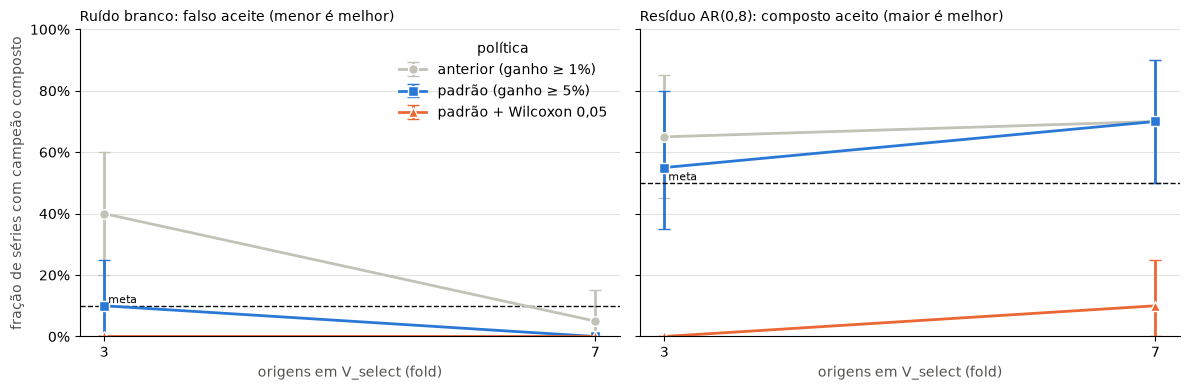

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
titles = {
    "white_noise": "Ruído branco: falso aceite (menor é melhor)",
    "ar_residual": "Resíduo AR(0,8): composto aceito (maior é melhor)",
}
colors = ["#c3c2b7", "#2a78d6", "#eb6834"]  # one fixed colour per policy
for ax, control in zip(axes, ["white_noise", "ar_residual"], strict=True):
    part = report.loc[control]
    for policy, marker, color in zip(POLICIES, ["o", "s", "^"], colors, strict=True):
        rows = part.xs(policy, level="policy")
        ax.errorbar(
            rows.index,
            rows["hybrid_champion_rate"],
            yerr=[
                rows["hybrid_champion_rate"] - rows["rate_ci_low"],
                rows["rate_ci_high"] - rows["hybrid_champion_rate"],
            ],
            marker=marker,
            markersize=7,
            markeredgecolor="white",
            color=color,
            linewidth=2,
            capsize=4,
            label=policy,
        )
    target = 0.10 if control == "white_noise" else 0.50  # ADR-0008 targets
    ax.axhline(target, color="#0b0b0b", linewidth=1, linestyle="--")
    ax.text(FOLDS[0], target, " meta", va="bottom", fontsize=8, color="#0b0b0b")
    ax.set_title(titles[control], loc="left", fontsize=10)
    ax.set_xlabel("origens em V_select (fold)", color="#52514e")
    ax.set_xticks(list(FOLDS))
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("fração de séries com campeão composto", color="#52514e")
axes[0].legend(frameon=False, title="política")
fig.tight_layout()

## 3. Conjunto de confirmação

Mesmas condições, outras séries. Se uma política fosse escolhida olhando a calibração, esta seria a conferência única.

In [5]:
confirmation = calibration_report(
    run_calibration(control_cases(N_SERIES, "confirmation"), FOLDS, POLICIES)
)
side_by_side = pd.concat(
    {
        "calibração": report["hybrid_champion_rate"],
        "confirmação": confirmation["hybrid_champion_rate"],
    },
    axis=1,
)
side_by_side.round(3)

calibração  confirmação
control     fold policy                                         
ar_residual 3    anterior (ganho ≥ 1%)         0.65         0.55
                 padrão (ganho ≥ 5%)           0.55         0.45
                 padrão + Wilcoxon 0,05        0.00         0.00
            7    anterior (ganho ≥ 1%)         0.70         0.60
                 padrão (ganho ≥ 5%)           0.70         0.60
                 padrão + Wilcoxon 0,05        0.10         0.25
white_noise 3    anterior (ganho ≥ 1%)         0.40         0.25
                 padrão (ganho ≥ 5%)           0.10         0.05
                 padrão + Wilcoxon 0,05        0.00         0.00
            7    anterior (ganho ≥ 1%)         0.05         0.00
                 padrão (ganho ≥ 5%)           0.00         0.00
                 padrão + Wilcoxon 0,05        0.00         0.00

## 4. Leitura dos resultados

Nesta execução (20 séries por controle e conjunto, `fh=7`, orçamento `smoke`; a calibração completa da ADR-0008 usou 50):

* **Com 3 origens, o limiar de ganho faz a maior diferença.** No ruído branco, a regra anterior (ganho ≥ 1%) deixa um híbrido virar campeão em 40% das séries de calibração (25% na confirmação); a padrão (≥ 5%), em 10% (5%). O custo é pequeno no resíduo AR: o ganho útil aceito cai de 65% para 55% (55% para 45% na confirmação).
* **Com 7 origens, a regra padrão cumpre a meta nos dois conjuntos:** nenhum falso aceite no ruído branco e 70% (calibração) e 60% (confirmação) dos ganhos úteis aceitos. Com 7 unidades até a regra anterior quase não aceita espúrios aqui (5% e 0%): o número de origens pesa tanto quanto o limiar.
* **O Wilcoxon continua trocando um erro pelo outro:** zera os falsos aceites, mas aceita só 0–25% dos ganhos úteis, mesmo com 7 unidades.
* **A confirmação fica na mesma faixa da calibração**, sempre um pouco abaixo no resíduo AR. Com 20 séries os intervalos de 95% têm ±20 pontos: use estes números como ilustração; a decisão se apoia na medição com 50 séries (ADR-0008, guia de seleção).

Por isso o padrão é ganho ≥ 5% com `fold="auto"` (7 origens quando a série comporta). Em séries curtas, que comportam menos origens, a regra fica entre as linhas de 3 e 7 desta tabela, e o experimento avisa. Limites: dois controles sintéticos diários, uma comparação híbrida por cadeia, um orçamento e uma semente de sessão.